# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Registration number:** 048  |  **Course:** Computer Vision Lab

In [1]:
!pip install -q medmnist opencv-python scikit-image scikit-learn matplotlib pandas

## Personal settings (first cell)

In [2]:
REG_NO = "048"
SEED = int(REG_NO[-2:])            # last two digits -> 48
last_digit = int(REG_NO[-1])       # 8

HOG_CELL  = (8, 8) if last_digit % 2 == 0 else (16, 16)   # 8 is even  -> 8x8
SIFT_GRID = 4 if last_digit <= 4 else 6                   # 8 is 5..9  -> 6x6 grid (36 keypoints)

print("Seed       :", SEED)
print("HOG cell   :", HOG_CELL)
print("SIFT grid  :", f"{SIFT_GRID}x{SIFT_GRID} ({SIFT_GRID**2} keypoints)")

Seed       : 48
HOG cell   : (8, 8)
SIFT grid  : 6x6 (36 keypoints)


In [3]:
import random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore")

CLASS_IDS   = [1, 5, 6, 7]                                # BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]

# Q1. Data setup (3 marks)

In [4]:
from medmnist import BloodMNIST

N_PER_CLASS = {"train": 100, "val": 30, "test": 30}
rng = np.random.default_rng(SEED)

def load_subset(split, n_per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs, labels = ds.imgs, ds.labels.flatten()
    X, y = [], []
    for new_label, cid in enumerate(CLASS_IDS):          # new labels 0..3
        idx = np.where(labels == cid)[0]
        chosen = rng.choice(idx, size=n_per_class, replace=False)   # chosen with the seed
        X.append(imgs[chosen]); y.append(np.full(n_per_class, new_label))
    X, y = np.concatenate(X), np.concatenate(y)
    perm = rng.permutation(len(y))                        # shuffle (seeded)
    return X[perm], y[perm]

X_tr_rgb, y_tr = load_subset("train", N_PER_CLASS["train"])
X_va_rgb, y_va = load_subset("val",   N_PER_CLASS["val"])
X_te_rgb, y_te = load_subset("test",  N_PER_CLASS["test"])

for name, X, y in [("train", X_tr_rgb, y_tr), ("val", X_va_rgb, y_va), ("test", X_te_rgb, y_te)]:
    counts = {CLASS_NAMES[i]: int(c) for i, c in enumerate(np.bincount(y, minlength=4))}
    print(f"{name:5s} | images shape: {X.shape} | labels shape: {y.shape} | class counts: {counts}")

100%|██████████| 156M/156M [00:03<00:00, 43.6MB/s]


train | images shape: (400, 64, 64, 3) | labels shape: (400,) | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | images shape: (120, 64, 64, 3) | labels shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | images shape: (120, 64, 64, 3) | labels shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


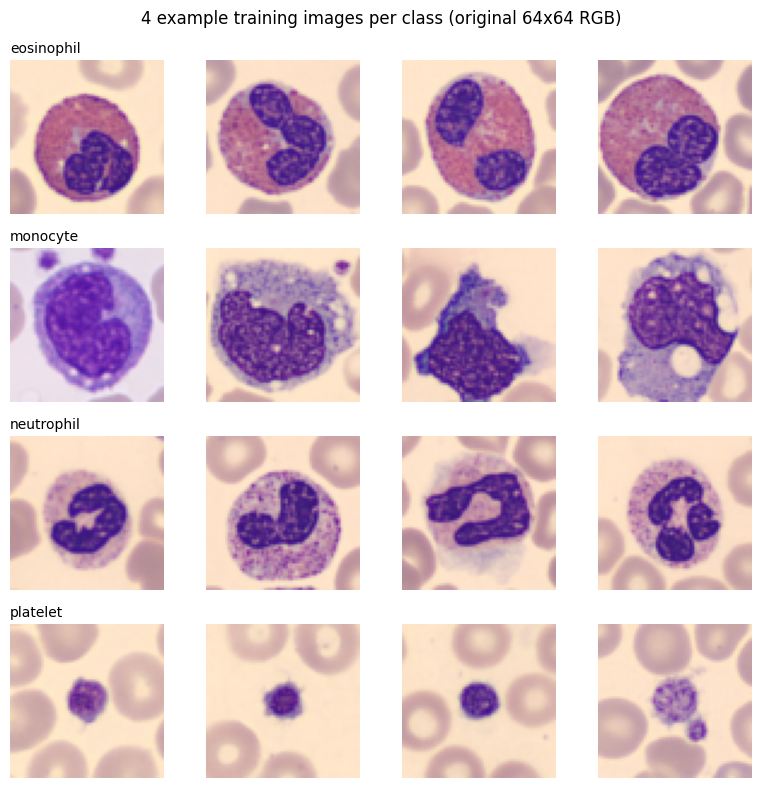

In [5]:
# Grid: 4 example images per class (rows = classes), from the training split
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r, cname in enumerate(CLASS_NAMES):
    idx = np.where(y_tr == r)[0][:4]
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_tr_rgb[i]); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(cname, loc="left", fontsize=10)
plt.suptitle("4 example training images per class (original 64x64 RGB)")
plt.tight_layout(); plt.show()

**Image preparation (fixed for everyone):** grayscale, then resize to 128 x 128.

In [6]:
def preprocess(rgb_imgs):
    out = []
    for im in rgb_imgs:
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
        g = cv2.resize(g, (128, 128), interpolation=cv2.INTER_LINEAR)
        out.append(g)
    return np.array(out, dtype=np.uint8)

X_tr, X_va, X_te = preprocess(X_tr_rgb), preprocess(X_va_rgb), preprocess(X_te_rgb)
print("Preprocessed shapes:", X_tr.shape, X_va.shape, X_te.shape, "| dtype:", X_tr.dtype)

Preprocessed shapes: (400, 128, 128) (120, 128, 128) (120, 128, 128) | dtype: uint8


# Q2. HOG + SVM (6 marks)

### (2) HOG feature length - hand calculation
Settings: image = 128 x 128, cell = 8 x 8, block = 2 x 2 cells, 9 orientations, block stride = 1 cell.

- Cells per side = 128 / 8 = **16**  → 16 x 16 cells
- Blocks per side = 16 − 2 + 1 = **15**  → 15 x 15 = 225 blocks
- Values per block = 2 x 2 cells x 9 orientations = **36**
- Total length = 225 x 36 = **8100**

In [7]:
def hog_features(img, visualize=False):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
               block_norm="L2-Hys", visualize=visualize, feature_vector=True)

def extract_hog(imgs):
    return np.array([hog_features(im) for im in imgs])

# hand-calculation check in code
cells = 128 // HOG_CELL[0]; blocks = cells - 2 + 1; per_block = 2 * 2 * 9
print(f"By hand: cells/side={cells}, blocks/side={blocks}, per block={per_block}, total={blocks*blocks*per_block}")

Xh_tr, Xh_va = extract_hog(X_tr), extract_hog(X_va)
print("HOG feature length from skimage:", Xh_tr.shape[1])
print("Train HOG matrix:", Xh_tr.shape, "| Val HOG matrix:", Xh_va.shape)

By hand: cells/side=16, blocks/side=15, per block=36, total=8100
HOG feature length from skimage: 8100
Train HOG matrix: (400, 8100) | Val HOG matrix: (120, 8100)


### (1) HOG pictures - one image per class

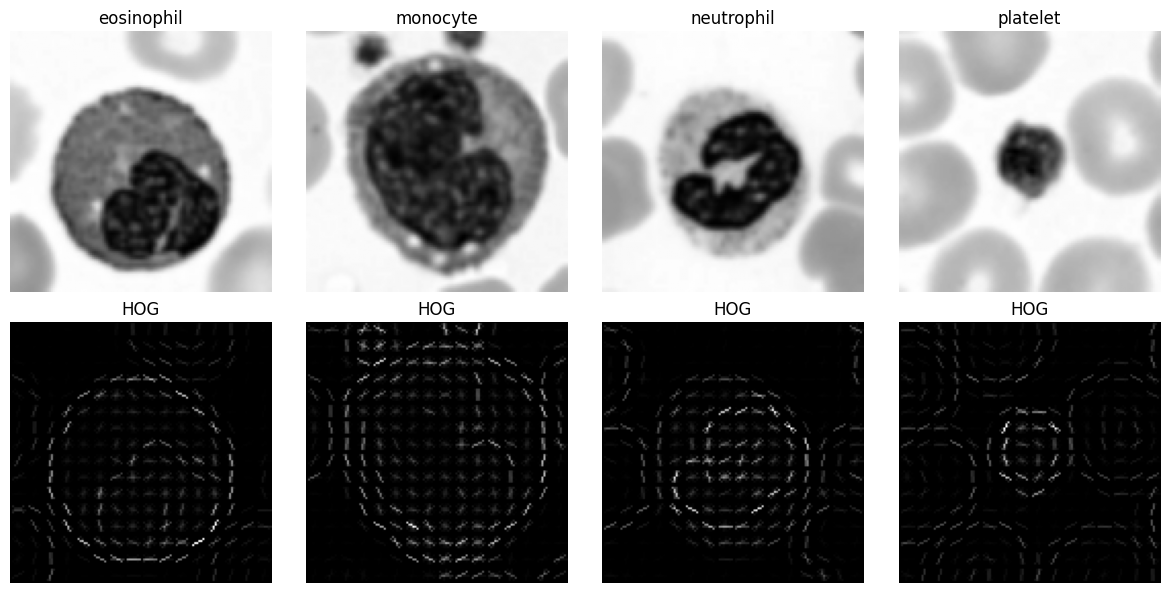

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c, cname in enumerate(CLASS_NAMES):
    i = np.where(y_tr == c)[0][0]
    _, hog_img = hog_features(X_tr[i], visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-8))
    axes[0, c].imshow(X_tr[i], cmap="gray"); axes[0, c].set_title(cname); axes[0, c].axis("off")
    axes[1, c].imshow(hog_img, cmap="gray");  axes[1, c].set_title("HOG"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

### (3) Train HOG + SVM (choose C on the validation set)

HOG + SVM: choosing C
  C = 0.1   -> validation accuracy = 0.7167
  C = 1     -> validation accuracy = 0.7000
  C = 10    -> validation accuracy = 0.7000
Best C = 0.1 (val acc 0.7167)
HOG + SVM (validation): accuracy = 0.7167 | macro-F1 = 0.7158
                 pred_eosinophil  pred_monocyte  pred_neutrophil  \
true_eosinophil               19              6                5   
true_monocyte                  4             21                5   
true_neutrophil               10              4               16   
true_platelet                  0              0                0   

                 pred_platelet  
true_eosinophil              0  
true_monocyte                0  
true_neutrophil              0  
true_platelet               30  


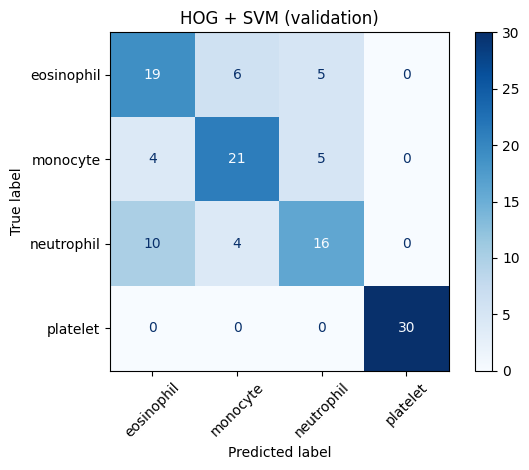

In [9]:
def tune_svm(Xtr, ytr, Xva, yva, Cs=(0.1, 1, 10)):
    best = None
    for C in Cs:
        clf = LinearSVC(C=C, max_iter=20000, random_state=SEED).fit(Xtr, ytr)
        acc = accuracy_score(yva, clf.predict(Xva))
        print(f"  C = {C:<5} -> validation accuracy = {acc:.4f}")
        if best is None or acc > best["acc"]:          # ties -> keeps the smaller C
            best = {"acc": acc, "C": C, "clf": clf}
    print(f"Best C = {best['C']} (val acc {best['acc']:.4f})")
    return best

def report(clf, X, y, title):
    pred = clf.predict(X)
    acc = accuracy_score(y, pred)
    f1  = f1_score(y, pred, average="macro")
    cm  = confusion_matrix(y, pred, labels=range(4))
    print(f"{title}: accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print(pd.DataFrame(cm, index=[f"true_{n}" for n in CLASS_NAMES],
                          columns=[f"pred_{n}" for n in CLASS_NAMES]))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=45)
    plt.title(title); plt.tight_layout(); plt.show()
    return acc, f1, cm

print("HOG + SVM: choosing C")
hog_best = tune_svm(Xh_tr, y_tr, Xh_va, y_va)
hog_clf = hog_best["clf"]
hog_val_acc, hog_val_f1, hog_val_cm = report(hog_clf, Xh_va, y_va, "HOG + SVM (validation)")

**HOG + SVM result (validation):** best C = 0.1, accuracy = 0.7167, macro-F1 = 0.7158. Platelet was perfect (30 of 30), and most errors were between eosinophil and neutrophil.

# Q3. SIFT + SVM (7 marks)

### (2) Normal SIFT detection on the training images

In [10]:
sift = cv2.SIFT_create()

kp_counts, kp_store = [], []
for im in X_tr:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps)); kp_store.append(kps)
kp_counts = np.array(kp_counts)

print(f"Average keypoints per image : {kp_counts.mean():.2f}")
print(f"Minimum keypoints per image : {kp_counts.min()}")
print(f"Maximum keypoints per image : {kp_counts.max()}")
print(f"Images with zero keypoints  : {(kp_counts == 0).sum()} out of {len(kp_counts)}")

Average keypoints per image : 69.97
Minimum keypoints per image : 11
Maximum keypoints per image : 175
Images with zero keypoints  : 0 out of 400


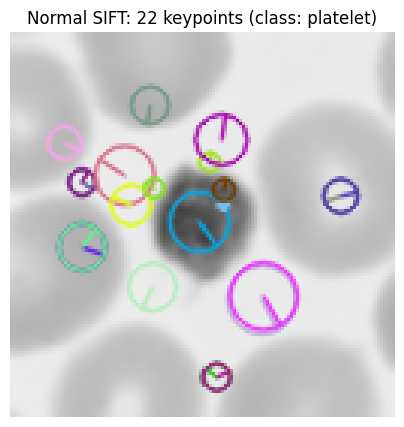

In [11]:
# draw keypoints on one image (first training image with at least one keypoint)
i = int(np.where(kp_counts > 0)[0][0])
vis = cv2.drawKeypoints(X_tr[i], kp_store[i], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Normal SIFT: {kp_counts[i]} keypoints (class: {CLASS_NAMES[y_tr[i]]})"); plt.show()

**Why a different number of keypoints is a problem for an SVM:** normal SIFT found between 11 and 175 keypoints per image (average 69.97), so each image would give a feature vector of a different length, but an SVM needs every image to have the same number of features in the same order.

### (2) Fixed grid of keypoints - feature length by hand
Settings: 6 x 6 grid, keypoint size 32, SIFT descriptor = 128 numbers per keypoint.

- Grid points = 6 x 6 = **36**
- Feature length = 36 x 128 = **4608**

In [12]:
KP_SIZE = 32

def make_grid_keypoints(grid=SIFT_GRID, img_size=128, kp_size=KP_SIZE):
    step = img_size / grid
    centers = (np.arange(grid) + 0.5) * step          # centres of a regular grid x grid layout
    return [cv2.KeyPoint(float(x), float(y), float(kp_size)) for y in centers for x in centers]

def sift_grid_features(img):
    kps = make_grid_keypoints()
    kps, des = sift.compute(img, kps)
    assert des is not None and des.shape == (SIFT_GRID ** 2, 128), "unexpected descriptor shape"
    return des.flatten() / 255.0                       # descriptors are in 0..255 -> scale to 0..1

def extract_sift(imgs):
    return np.array([sift_grid_features(im) for im in imgs])

print("By hand:", SIFT_GRID**2, "x 128 =", SIFT_GRID**2 * 128)
Xs_tr, Xs_va = extract_sift(X_tr), extract_sift(X_va)
print("SIFT grid feature length:", Xs_tr.shape[1])
print("Train SIFT matrix:", Xs_tr.shape, "| Val SIFT matrix:", Xs_va.shape)

By hand: 36 x 128 = 4608
SIFT grid feature length: 4608
Train SIFT matrix: (400, 4608) | Val SIFT matrix: (120, 4608)


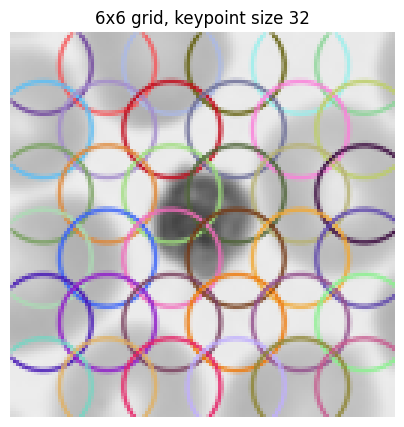

In [13]:
# picture of the grid positions (sanity check)
g = cv2.cvtColor(X_tr[0], cv2.COLOR_GRAY2BGR)
g = cv2.drawKeypoints(g, make_grid_keypoints(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(g[..., ::-1]); plt.axis("off")
plt.title(f"{SIFT_GRID}x{SIFT_GRID} grid, keypoint size {KP_SIZE}"); plt.show()

### (3) Train SIFT + SVM (choose C on the validation set)

SIFT + SVM: choosing C
  C = 0.1   -> validation accuracy = 0.8083
  C = 1     -> validation accuracy = 0.8333
  C = 10    -> validation accuracy = 0.8583
Best C = 10 (val acc 0.8583)
SIFT (grid) + SVM (validation): accuracy = 0.8583 | macro-F1 = 0.8564
                 pred_eosinophil  pred_monocyte  pred_neutrophil  \
true_eosinophil               20              7                3   
true_monocyte                  2             28                0   
true_neutrophil                4              0               26   
true_platelet                  0              0                1   

                 pred_platelet  
true_eosinophil              0  
true_monocyte                0  
true_neutrophil              0  
true_platelet               29  


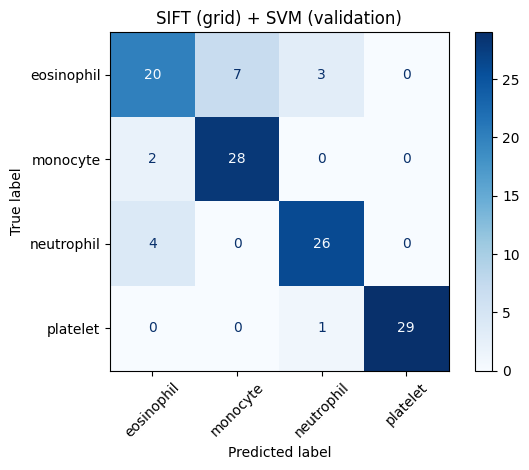

In [14]:
print("SIFT + SVM: choosing C")
sift_best = tune_svm(Xs_tr, y_tr, Xs_va, y_va)
sift_clf = sift_best["clf"]
sift_val_acc, sift_val_f1, sift_val_cm = report(sift_clf, Xs_va, y_va, "SIFT (grid) + SVM (validation)")

**SIFT + SVM result (validation):** best C = 10, accuracy = 0.8583, macro-F1 = 0.8564. Most errors were eosinophil predicted as monocyte (7) and eosinophil predicted as neutrophil (3).

# Q4. Robustness (6 marks)

### (1) Prediction - written BEFORE running the test evaluation
- **Rotation (20°):** I think **HOG** will lose more accuracy. HOG stores gradient orientations in fixed 8 x 8 cells at fixed positions (8100 numbers), so rotating the cell changes both the orientation bins and which cell the edges fall in. The SIFT grid uses large 32 x 32 patches that average over a wider area, so a 20° turn changes its descriptors less.
- **Noise (σ = 0.05):** I think **HOG** will lose more accuracy. HOG works directly on pixel gradients inside small 8 x 8 cells, and noise creates many random gradients there. SIFT smooths the image with a Gaussian and pools gradients over big 32 x 32 patches, so the noise averages out.

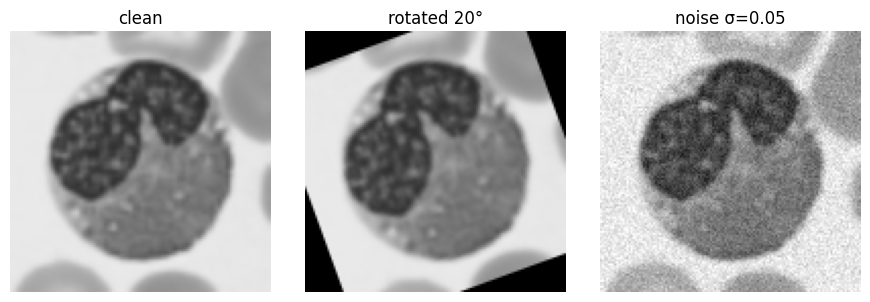

In [15]:
def rotate_imgs(imgs, angle=20):
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return np.array([cv2.warpAffine(im, M, (128, 128), flags=cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_CONSTANT, borderValue=0) for im in imgs])

def noisy_imgs(imgs, sigma=0.05, seed=SEED):
    r = np.random.default_rng(seed)
    x = imgs.astype(np.float32) / 255.0                 # scale to 0..1
    x = np.clip(x + r.normal(0.0, sigma, x.shape), 0.0, 1.0)
    return np.round(x * 255).astype(np.uint8)           # back to uint8 (SIFT needs 8-bit)

X_te_rot, X_te_noise = rotate_imgs(X_te, 20), noisy_imgs(X_te, 0.05)

# sanity check picture
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, t in zip(axes, [X_te[0], X_te_rot[0], X_te_noise[0]], ["clean", "rotated 20°", "noise σ=0.05"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

### (4) Frozen models evaluated on the test set (only place the test set is used)

In [16]:
# Models are frozen: hog_clf and sift_clf were trained on the training set only; nothing is refitted here.
conditions = {"Clean": X_te, "Rotated 20°": X_te_rot, "Noisy σ=0.05": X_te_noise}

results = {"HOG + SVM": {}, "SIFT + SVM": {}}
for cname, imgs in conditions.items():
    results["HOG + SVM"][cname]  = accuracy_score(y_te, hog_clf.predict(extract_hog(imgs)))
    results["SIFT + SVM"][cname] = accuracy_score(y_te, sift_clf.predict(extract_sift(imgs)))

table = pd.DataFrame(results).T
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
print("Test-set accuracy:")
display(table.round(4))

drops = pd.DataFrame({"Drop under rotation": table["Clean accuracy"] - table["Rotated accuracy"],
                      "Drop under noise":    table["Clean accuracy"] - table["Noisy accuracy"]})
print("Accuracy drop (clean - changed):")
display(drops.round(4))

Test-set accuracy:


,Clean accuracy,Rotated accuracy,Noisy accuracy
HOG + SVM,0.6917,0.5833,0.5167
SIFT + SVM,0.8333,0.3333,0.8250


Accuracy drop (clean - changed):


,Drop under rotation,Drop under noise
HOG + SVM,0.1083,0.1750
SIFT + SVM,0.5000,0.0083


### (1) Was my prediction correct?
My prediction was only half right: I was wrong about rotation, where HOG dropped from 0.6917 to 0.5833 (−0.1083) but SIFT dropped much more, from 0.8333 to 0.3333 (−0.5000). I was right about noise, where HOG dropped from 0.6917 to 0.5167 (−0.1750) while SIFT barely changed, from 0.8333 to 0.8250 (−0.0083). A likely reason is that my fixed-grid SIFT does not estimate orientation, so a 20° turn moves the cell content away from the grid points it learned, while its large 32 x 32 patches smooth out the noise.

# Q5. Short answers and AI log (3 marks)

### (1a) Why does HOG use block normalisation?
Gradient strengths change with lighting and contrast, so the same shape can give very different numbers. Normalising each block of cells puts the histograms on a common scale, so HOG depends much less on brightness and contrast.

### (1b) Why is it wrong to choose C using the test set?
The test set is supposed to be unseen data. If C is picked because it scores best on the test set, the test set has helped build the model, so the final accuracy looks better than it really is. C should be chosen on the validation set instead.

### (1) Which two classes were confused most? (computed from the validation confusion matrices - test set not touched)

In [17]:
def top_confusions(cm, k=3):
    pairs = []
    for i in range(4):
        for j in range(i + 1, 4):
            pairs.append((cm[i, j] + cm[j, i], CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j], cm[j, i]))
    pairs.sort(reverse=True)
    for tot, a, b, ab, ba in pairs[:k]:
        print(f"  {a} <-> {b}: {tot} errors  ({a} predicted as {b}: {ab}, {b} predicted as {a}: {ba})")

print("HOG + SVM, most confused pairs (validation):");  top_confusions(hog_val_cm)
print("SIFT + SVM, most confused pairs (validation):"); top_confusions(sift_val_cm)

HOG + SVM, most confused pairs (validation):
  eosinophil <-> neutrophil: 15 errors  (eosinophil predicted as neutrophil: 5, neutrophil predicted as eosinophil: 10)
  eosinophil <-> monocyte: 10 errors  (eosinophil predicted as monocyte: 6, monocyte predicted as eosinophil: 4)
  monocyte <-> neutrophil: 9 errors  (monocyte predicted as neutrophil: 5, neutrophil predicted as monocyte: 4)
SIFT + SVM, most confused pairs (validation):
  eosinophil <-> monocyte: 9 errors  (eosinophil predicted as monocyte: 7, monocyte predicted as eosinophil: 2)
  eosinophil <-> neutrophil: 7 errors  (eosinophil predicted as neutrophil: 3, neutrophil predicted as eosinophil: 4)
  neutrophil <-> platelet: 1 errors  (neutrophil predicted as platelet: 0, platelet predicted as neutrophil: 1)


**Answer:** Eosinophil and neutrophil were confused most: 15 errors for HOG (5 + 10) and 7 for SIFT (3 + 4), 22 in total. For SIFT the single biggest pair was eosinophil and monocyte (9 errors), so eosinophil is the class that causes most mix-ups, while platelet was almost never confused (0 HOG errors, 1 SIFT error). Eosinophils are mainly recognised by their red-orange granules, and grayscale throws that colour away, leaving only brightness and texture, which look similar to neutrophils and monocytes.

### (1) AI log

| Prompt (one line) | What I changed | How I checked it was correct |
|---|---|---|
| "Here is my lab task, my registration number is 048, write the code for each question" | Used my own settings (seed 48, HOG 8x8, SIFT 6x6 grid) and wrote my prediction and answers from my own outputs | Printed shapes and class counts (400/120/120 images, 100/30/30 per class); viewed the 4x4 image grid |
| "Extract HOG and fixed-grid SIFT features" | Kept the settings for my registration number | Printed feature lengths (HOG 8100, SIFT 4608) and matched my hand calculations; viewed the HOG pictures and the SIFT grid on an image |
| "Test rotation 20° and Gaussian noise sigma 0.05 on the frozen models" | Applied changes to images before feature extraction | Plotted clean / rotated / noisy images side by side; checked C was chosen on validation and the test set was used only in Q4 |